# Lab 3.12 — Which expert gets the token and the gradient?

Branch from the dense Lab 3.9 checkpoint. Replace the final block’s MLP with four equally wide experts. Each token visits one expert. Compare two training runs with exactly the same initial weights and batches.

## Route and dispatch

A router produces four probabilities per token. We send the token to its top expert and multiply its output by the selected probability, which lets the task loss train the router. Copy the dense MLP into each expert to control initialization. The gate multiplier changes the initial output even with identical copies.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from copy import deepcopy
from llm_lab.experiments import loads_base, adaptation, windows, loss
class Experts(nn.Module):
    def __init__(self,mlp):
        super().__init__()
        self.experts = nn.ModuleList(deepcopy(mlp) for _ in range(4))
        self.router = nn.Linear(mlp.c_fc.in_features,4)
    def forward(self,x):
        rows = x.reshape(-1,x.size(-1))
        probs = self.router(rows).softmax(-1)
        gates,route = probs.max(-1)
        out = torch.zeros_like(rows)
        self.counts = route.bincount(minlength=4)
        fraction = self.counts / route.numel()
        self.balance = 4 * (fraction * probs.mean(0)).sum()
        for i,expert in enumerate(self.experts):
            mask = route == i
            if mask.any():
                out[mask] = expert(rows[mask])*gates[mask,None]
        return out.reshape_as(x)
initial,alphabet = loads_base()
initial.requires_grad_(False)
moe = Experts(initial.h[-1].mlp).requires_grad_(True)
initial.h[-1].mlp = moe
initial(torch.tensor([[1]])).sum().backward()
print("One token routed:",moe.counts.tolist())
print("Experts receiving gradients:",[e.c_fc.weight.grad is not None for e in moe.experts])
initial.zero_grad()
moe.balance = moe.balance.detach()

One token routed: [0, 1, 0, 0]
Experts receiving gradients: [False, True, False, False]


## Compare load with and without a balancing term

The auxiliary loss multiplies each expert’s hard assignment fraction by its mean soft probability, then sums over experts. A heavily used expert with high probability increases that penalty. Use the same held-out windows to inspect final loads and language-model loss. Equal usage alone cannot establish that experts learned different language skills.

Coefficient 0.0 expert loads [0, 4096, 0, 0] held-out nats 3.6299095153808594
Coefficient 0.1 expert loads [1754, 2342, 0, 0] held-out nats 3.672720432281494
Out[2]: PosixPath('checkpoints/lab312/routing_comparison.npz')


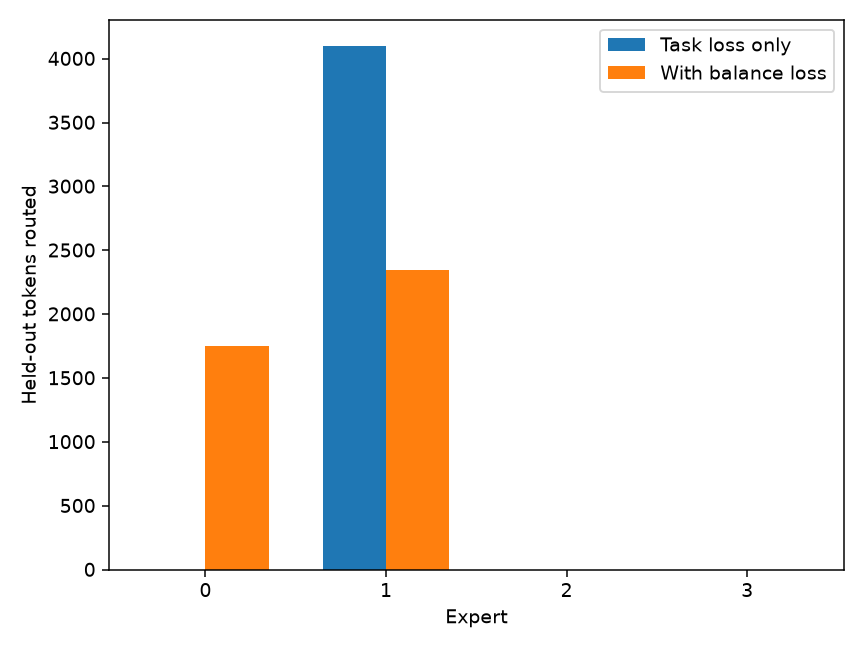

In [2]:
train,schedule,held = adaptation(alphabet)
loads, scores = [], []
for coefficient in (0.,.1):
    model = deepcopy(initial)
    layer = model.h[-1].mlp
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=.002)
    for starts in schedule:
        opt.zero_grad()
        main = loss(model,windows(train,starts))
        (main+coefficient*layer.balance).backward()
        opt.step()
    with torch.no_grad():
        scores.append(loss(model,held).item())
        loads.append(layer.counts.tolist())
    print("Coefficient",coefficient,"expert loads",loads[-1],"held-out nats",scores[-1])
assert all(sum(row)==held[0].numel() for row in loads)
x = np.arange(4)
for i,label in enumerate(["Task loss only","With balance loss"]):
    plt.bar(x+i*.35,loads[i],width=.35,label=label)
plt.xticks(x+.175,range(4)); plt.ylabel("Held-out tokens routed"); plt.xlabel("Expert"); plt.legend()
show(312,"expert_load")
record(312,"routing_comparison",loads=loads,scores=scores,coefficients=[0,.1])

## Reading the result

Without the balancing term, one expert received all 4,096 held-out tokens. With coefficient 0.1, two experts received tokens and the other two stayed idle. Held-out loss changed from 3.63 to 3.67. What extra observation would convince you that the two active experts learned different functions?

This implementation runs four small experts on one CPU. Sending selected rows to experts on different devices adds a communication problem even when each token still visits only one expert. [Switch Transformers paper](https://www.jmlr.org/papers/v23/21-0998.html)